/var/folders/hl/6pbc75td3hgd89t5rhpbcqw80000gn/T/ipykernel_12420/2460150893.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  usreps['district'] = usreps['district'].astype(str).str.replace(r'\.0$', '', regex=True)
/var/folders/hl/6pbc75td3hgd89t5rhpbcqw80000gn/T/ipykernel_12420/2460150893.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  usreps['district'] = usreps['district'].astype(str).str.zfill(2)
/var/folders/hl/6pbc75td3hgd89t5rhpbcqw80000gn/T/ipykernel_12420/2460150893.py:39: SettingWithCopyWa

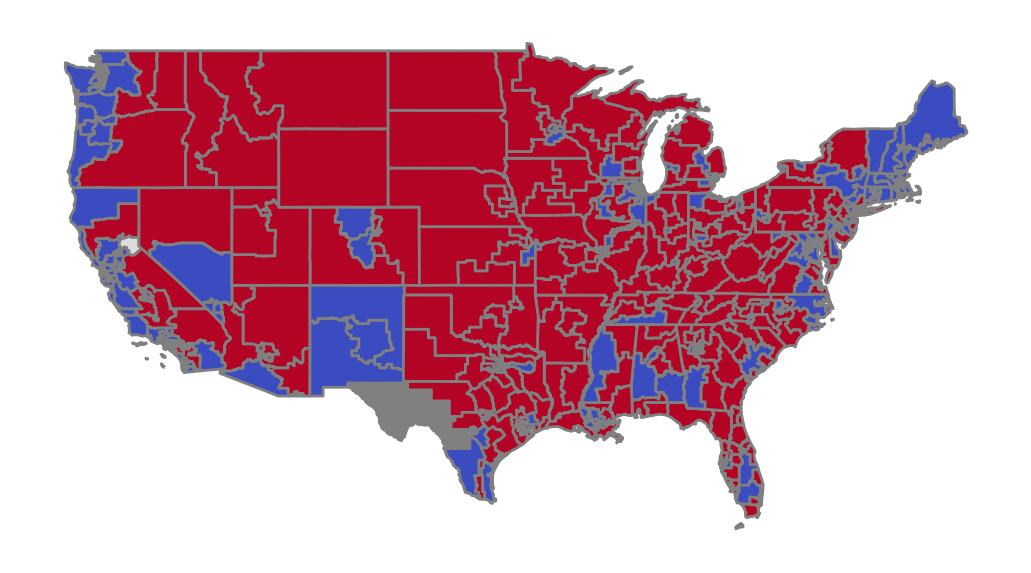

In [192]:
#------- Import Tools --------
import pandas as pd
import geopandas as gpd
import numpy as np
import rasterio
%config InlineBackend.figure_format ='retina'

# Import US 116th Congressional Districts Shapefile
usdistricts = gpd.read_file('/Users/samking/Desktop/Data Project/usdistricts/congress.shp')

# Create a list of states and territory FIPS to remove for mapping (HI and AK)
exclude_statefps = ['0200', '1501', '1502']

# Filtering the DataFrame to remove territories
lower_48 = usdistricts[~usdistricts['fips'].isin(exclude_statefps)]

# Import the US Congressional Dataset
uscongress = pd.read_csv('/Users/samking/Desktop/Data Project/legislators-current.csv')
uscongress['party'].head(25)

# Create a code for the party strings to facilitate color coding
conditions = [
    uscongress['party'].str.contains('dem', case=False, na=False),
    uscongress['party'].str.contains('rep', case=False, na=False),
    uscongress['party'].str.contains('ind', case=False, na=False),
]
choices = [1, 3, 2]
uscongress['partycode'] = np.select(conditions, choices, default=0)

# Narrow to only Representatives
uscongress['Representative'] = uscongress['type'].isin(['rep'])
usreps = uscongress[uscongress['Representative']]

# Standardize the CD numbers to clean up district codes
usreps['district'] = usreps['district'].astype(str).str.replace(r'\.0$', '', regex=True)
usreps['district'] = usreps['district'].astype(str).str.zfill(2)

# Merge state and district for unique identifiers
usreps['districtcode'] = usreps['state'].astype(str)+usreps['district'].astype(str)
usreps

# Merge the map file with the representative information to attach representatives to their district
mapwreps = lower_48.merge(usreps, left_on='id', right_on='districtcode', how='left', indicator=True)

# Generate plot to display map
base = mapwreps.plot(color='grey')

#  edgecolor='Black',
mapwreps.plot(column='partycode', ax=base, figsize=(150,25), edgecolor='grey', cmap='coolwarm').set_axis_off()

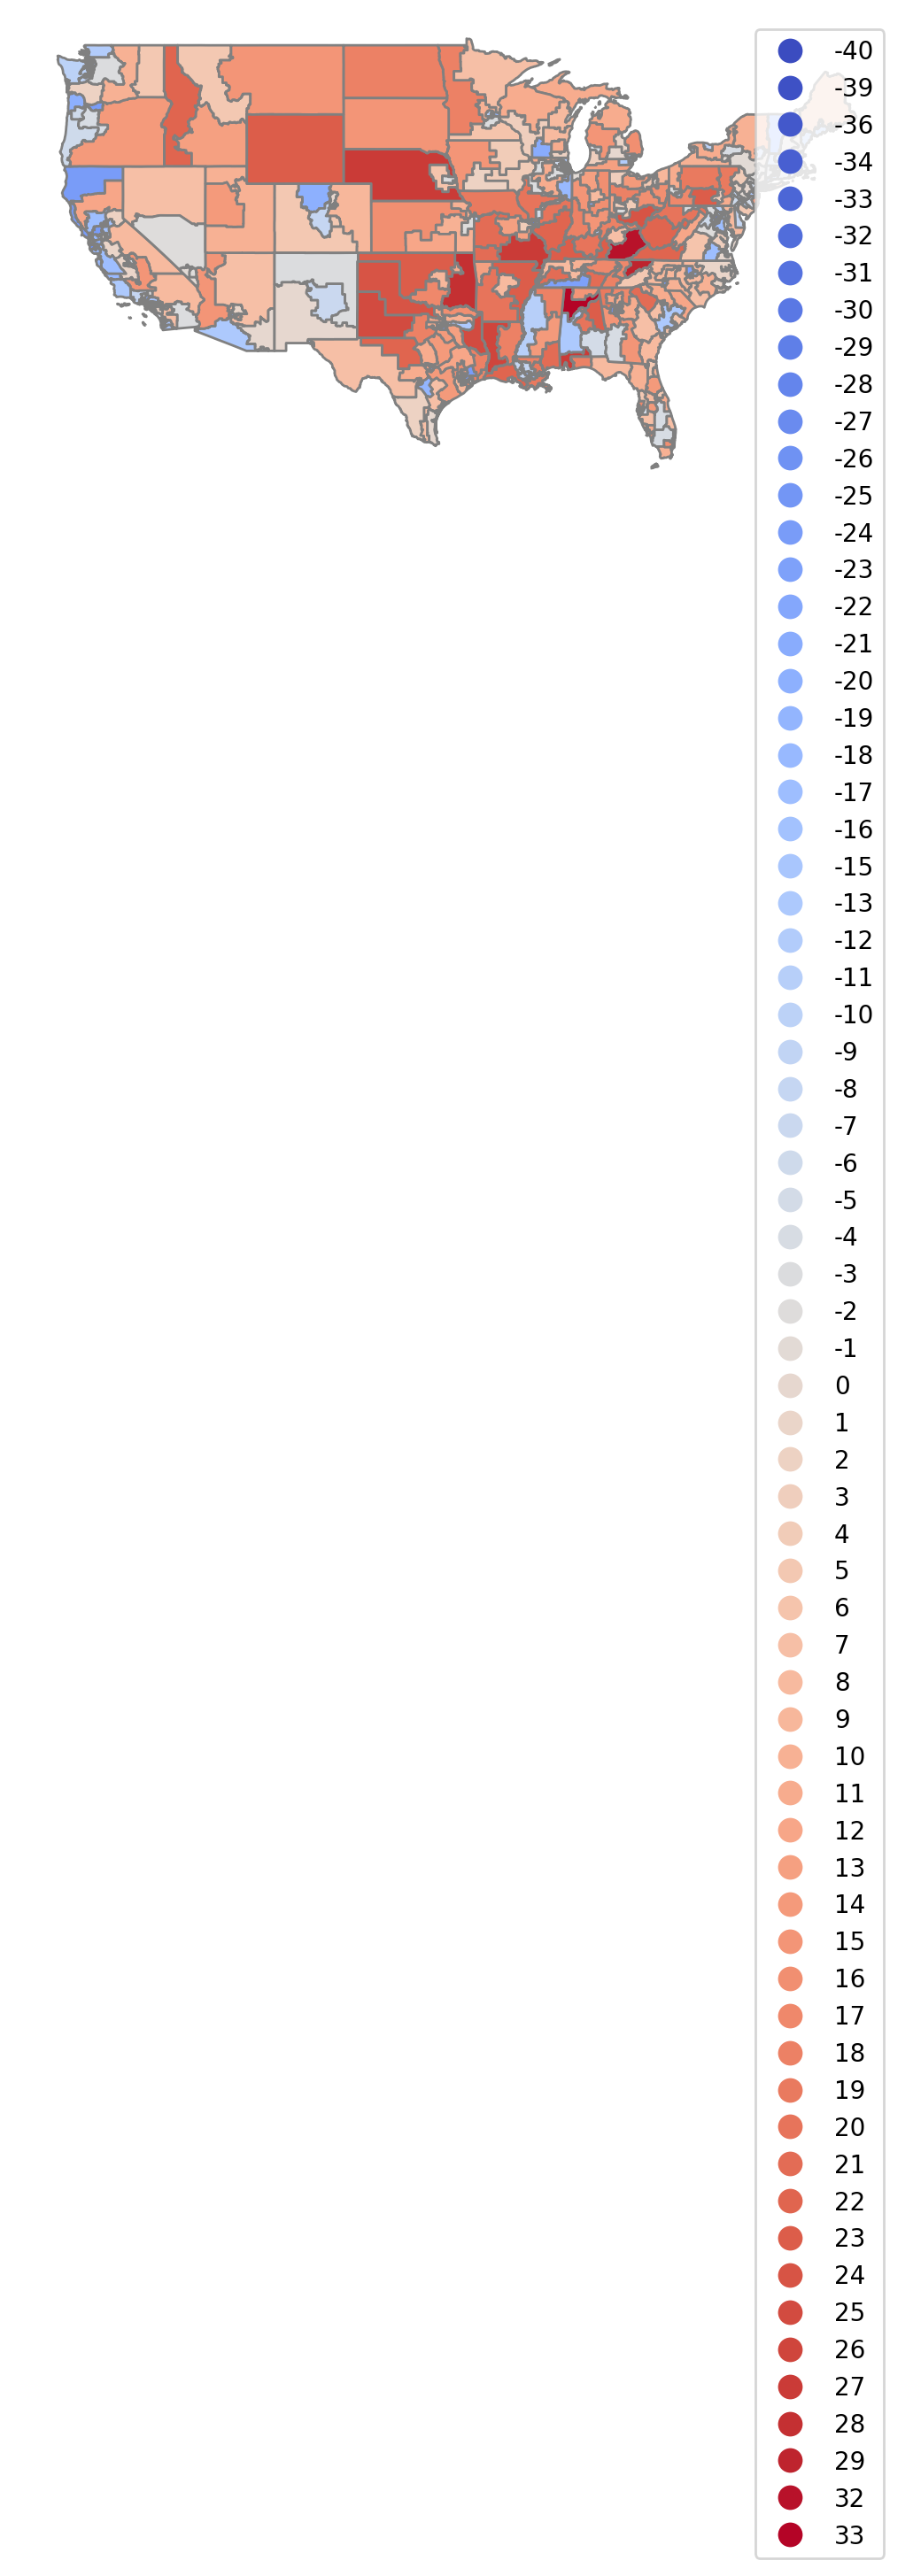

In [194]:
# Read in scraped Cook PVI data for all CDs
cookpvi = pd.read_csv('/Users/samking/Desktop/Data Project/cook_pvi_2026_districts.csv')

# Standardize CD names to match existing codes
cookpvi['District'] = cookpvi['District'].str.replace('-AL','-00')
cookpvi['District'] = cookpvi['District'].str.replace("-", '')

# Rename the _merge column in mapwreps to create a new one to check the merge with the Cook data
mapwreps.rename(columns={'_merge':'_mergeOLD'}, inplace=True)

# Append Cook data to CD shape file
cookshp = mapwreps.merge(cookpvi, left_on='id', right_on='District', how='left', indicator=True)

# Replace R+ and D+ with a scale (D minus, R plus to match cool-warm scale) to map Cook score
#cookshp['PVI_Prior_map'] = cookshp['PVI_Prior'].str.replace("R+", '-')
#cookshp['PVI_Prior_map'] = cookshp['PVI_Prior_map'].str.replace("D+", '+')

# Generate plot to display map
#ax = mapwreps.plot(color='grey')
#cookshp.plot(column='PVI_Prior_map', ax=ax, figsize=(150,25), edgecolor='grey', cmap='coolwarm')

# Read in scraped Cook PVI data for all CDs
cookpvi = pd.read_csv('/Users/samking/Desktop/Data Project/cook_pvi_2026_districts.csv')

# Standardize CD names to match existing codes
cookpvi['District'] = cookpvi['District'].str.replace('-AL','-00')
cookpvi['District'] = cookpvi['District'].str.replace("-", '')

# Rename the _merge column in mapwreps to create a new one to check the merge with the Cook data
mapwreps.rename(columns={'_merge':'_mergeOLD'}, inplace=True)

# Append Cook data to CD shape file
cookshp = mapwreps.merge(cookpvi, left_on='id', right_on='District', how='left', indicator=True)

# Replace R+ and D+ with a scale (D minus, R plus to match cool-warm scale) to map Cook score
def pvi_to_num(s):
    if pd.isna(s):
        return pd.NA
    if s == "EVEN":
        return 0
    party, val = s.split("+")
    return (-int(val)) if party == "D" else int(val)

cookshp["pvi_2026_num"] = cookshp["PVI_2026"].map(pvi_to_num)
cookshp["pvi_prior_num"] = cookshp["PVI_Prior"].map(pvi_to_num)

# Generate plot to display map
base = mapwreps.plot(color='grey')
cookshp.plot(column='pvi_prior_num', ax=base, figsize=(150,25), edgecolor='grey', cmap='coolwarm', legend=True).set_axis_off()

In [ ]:
# Merge check tools
#print(len(cookshp))
#print(cookshp['party'].isna().sum(), "NaN of", len(mapwreps))
#print(cookshp['party'].dtype)
#print(cookshp['party'].value_counts(dropna=False).head())
#print(cookshp['_merge'].value_counts())

In [127]:
cookshp.head(25)

,congress,fips,id,name,geometry,last_name,first_name,middle_name,suffix,nickname,...,District,district code,Incumbent,Party,PVI_Prior,PVI_2026,Rank,_merge,pvi_2026_num,pvi_prior_num
0,120,0101,AL01,AL01 District,"MULTIPOLYGON (((-86.18725 30.99403, -86.45471 ...",Moore,Barry,NaN,NaN,NaN,...,AL01,101.0,OPEN (Moore),R,R+27,R+17,392.0,both,17,27
1,120,0102,AL02,AL02 District,"POLYGON ((-84.99973 32.50814, -84.99983 32.504...",Figures,Shomari,Coleman,NaN,NaN,...,AL02,102.0,Shomari Figures,D,D+5,R+7,260.0,both,7,-5
2,120,0103,AL03,AL03 District,"POLYGON ((-85.51214 34.51837, -85.47045 34.328...",Rogers,Mike,NaN,NaN,NaN,...,AL03,103.0,Mike Rogers,R,R+23,R+23,422.0,both,23,23
3,120,0104,AL04,AL04 District,"POLYGON ((-85.51362 34.52386, -85.56039 34.489...",Aderholt,Robert,B.,NaN,NaN,...,AL04,104.0,Robert Aderholt,R,R+33,R+33,435.0,both,33,33
4,120,0105,AL05,AL05 District,"POLYGON ((-85.58315 34.86037, -85.62707 34.831...",Strong,Dale,NaN,NaN,NaN,...,AL05,105.0,Dale Strong,R,R+15,R+15,364.0,both,15,15
5,120,0106,AL06,AL06 District,"POLYGON ((-87.03982 33.68746, -87.04064 33.728...",Palmer,Gary,J.,NaN,NaN,...,AL06,106.0,Gary Palmer,R,R+20,R+17,391.0,both,17,20
6,120,0107,AL07,AL07 District,"POLYGON ((-88.44868 31.42061, -88.44875 31.420...",Sewell,Terri,A.,NaN,NaN,...,AL07,107.0,Terri Sewell,D,D+13,D+10,125.0,both,-10,-13
7,120,0501,AR01,AR01 District,"POLYGON ((-90.14837 34.99472, -90.14836 34.994...",Crawford,Eric,A.,NaN,Rick,...,AR01,501.0,Rick Crawford,R,R+23,R+23,421.0,both,23,23
8,120,0502,AR02,AR02 District,"POLYGON ((-92.80975 35.72242, -92.63115 35.718...",Hill,J.,French,NaN,NaN,...,AR02,502.0,French Hill,R,R+8,R+8,276.0,both,8,8
9,120,0503,AR03,AR03 District,"POLYGON ((-94.43679 35.24673, -94.43101 35.393...",Womack,Steve,NaN,NaN,NaN,...,AR03,503.0,Steve Womack,R,R+13,R+13,352.0,both,13,13


In [162]:
## Create a column of total change in Cook rating
#cookshp['pvi_change']=cookshp['pvi_2026_num'].astype(int)-cookshp['pvi_prior_num'].astype(int)
#cookshp['pvi_change']

In [160]:
print((cookshp["pvi_prior_num"] < 0).sum(), (cookshp["pvi_prior_num"] > 0).sum(), (cookshp['pvi_prior_num'] == 0).sum())

205 218 9


<Axes: >

In [166]:
col = "pvi_prior_num"                      # must be float64 (D negative, R positive)
vmin, vmax = cookshp[col].min(), cookshp[col].max()   # about -40 and +33
midpoint = 1 - vmax / (vmax + abs(vmin))              # about 0.55

cmap = shiftedColorMap(matplotlib.colormaps["RdBu_r"], midpoint=midpoint, name="pvi_shifted")

ax = mapwreps.plot(color="grey")
cookshp.plot(column=col, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
             edgecolor="grey", figsize=(150, 25))

AttributeError: module 'matplotlib.pyplot' has no attribute 'register_cmap'

In [196]:
pip install dash plotly pandas


182619.08s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 37.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 45.4 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [203]:
import numpy as np
import pandas as pd

cookpvi = pd.read_csv('/Users/samking/Desktop/Data Project/cook_pvi_2026_districts.csv')
cookpvi['District'] = cookpvi['District'].str.replace('-AL', '-00').str.replace('-', '')

def pvi_to_num(s):
    if pd.isna(s):
        return np.nan
    if s == "EVEN":
        return 0.0
    party, val = s.split("+")
    return -float(val) if party == "D" else float(val)

cookpvi["pvi_2026_num"] = cookpvi["PVI_2026"].map(pvi_to_num)
cookpvi["pvi_prior_num"] = cookpvi["PVI_Prior"].map(pvi_to_num)

out = mapwreps[["id", "geometry"]].merge(cookpvi, left_on="id", right_on="District", how="left")
out = out.to_crs(epsg=4326)                       # Plotly expects lat/lon
out["geometry"] = out.geometry.simplify(0.01)     # shrinks the file a lot
out.to_file("/Users/samking/Desktop/Data Project/cd_pvi.geojson", driver="GeoJSON")

/Users/samking/miniconda3/lib/python3.12/site-packages/shapely/constructive.py:863: RuntimeWarning: invalid value encountered in simplify_preserve_topology
  return lib.simplify_preserve_topology(geometry, tolerance, **kwargs)


In [210]:
import geopandas as gpd
import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html

# ---- 1. LOAD THE PRE-MERGED MAP DATA ----
gdf = gpd.read_file("/Users/samking/Desktop/Data Project/cd_pvi.geojson")

# Plain table (no geometry) for the histogram
table = pd.DataFrame(gdf.drop(columns="geometry"))

# ---- 2. BUILD THE MAP ----
# The geojson only needs shapes and the id used to match them to the data
geo = gdf[["id", "geometry"]].__geo_interface__

map_fig = px.choropleth(
    gdf,
    geojson=geo,
    locations="id",
    featureidkey="properties.id",
    color="pvi_prior_num",
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    scope="usa",
    hover_name="id",
    hover_data={
        "id": False,
        "Incumbent": True,
        "Party": True,
        "PVI_Prior": True,
        "PVI_2026": False,
        "pvi_prior_num": False,
    },
    labels={"pvi_prior_num": "PVI Score"},
)
map_fig.update_traces(marker_line_color="grey", marker_line_width=0.3)
map_fig.update_layout(margin=dict(l=0, r=0, t=0, b=0))

map_fig2 = px.choropleth(
    gdf,
    geojson=geo,
    locations='id',
    featureidkey='properties.id',
    color="pvi_2026_num",
    color_continuous_scale='RdBu_r',
    color_continuous_midpoint=0,
    scope='usa',
    hover_name='id',
    hover_data={
        'id': False,
        'Incumbent': True,
        'Party': True,
        'PVI_Prior': False,
        'PVI_2026': True,
        'pvi_prior_num': False,
    },
    labels={'pvi_2026_num': 'PVI Score'},
)
map_fig2.update_traces(marker_line_color='grey', marker_line_width=0.3)
map_fig2.update_layout(margin=dict(l=0, r=0, t=0, b=0))

# ---- 3. BUILD THE HISTOGRAM ----
hist_fig = px.histogram(
    table,
    x="pvi_2026_num",
    color="Party",
    nbins=40,
    color_discrete_map={"D": "royalblue", "R": "firebrick", "I": "gray"},
    labels={"pvi_2026_num": "PVI (D negative, R positive)"},
)

# ---- 4. BUILD THE APP ----
app = Dash(__name__)

app.layout = html.Div([
    html.H1("2026 Cook PVI by Congressional District"),
    html.H3("Map (PVI_Prior)"),
    dcc.Graph(figure=map_fig),
    html.H3("Map (PVI 2026"),
    dcc.Graph(figure=map_fig2),
    html.H3("Distribution of districts by PVI_2026"),
    dcc.Graph(figure=hist_fig),
])

# ---- 5. RUN IT ----
if __name__ == "__main__":
    app.run(debug=True)

In [206]:
out

,id,geometry,District,district code,Incumbent,Party,PVI_Prior,PVI_2026,Rank,pvi_2026_num,pvi_prior_num
0,AL01,"MULTIPOLYGON (((-86.18725 30.99403, -87.59883 ...",AL01,101.0,OPEN (Moore),R,R+27,R+17,392.0,17.0,27.0
1,AL02,"POLYGON ((-84.99973 32.50814, -84.96876 32.393...",AL02,102.0,Shomari Figures,D,D+5,R+7,260.0,7.0,-5.0
2,AL03,"POLYGON ((-85.51214 34.51837, -85.1844 32.8613...",AL03,103.0,Mike Rogers,R,R+23,R+23,422.0,23.0,23.0
3,AL04,"POLYGON ((-85.51362 34.52386, -85.56039 34.489...",AL04,104.0,Robert Aderholt,R,R+33,R+33,435.0,33.0,33.0
4,AL05,"POLYGON ((-85.58315 34.86037, -85.62707 34.831...",AL05,105.0,Dale Strong,R,R+15,R+15,364.0,15.0,15.0
...,...,...,...,...,...,...,...,...,...,...,...
428,WI07,"MULTIPOLYGON (((-89.22375 44.68137, -89.96402 ...",WI07,5507.0,OPEN (Tiffany),R,R+11,R+11,332.0,11.0,11.0
429,WI08,"MULTIPOLYGON (((-89.22482 44.2434, -89.22382 4...",WI08,5508.0,Tony Wied,R,R+8,R+8,285.0,8.0,8.0
430,WV01,"POLYGON ((-80.22099 37.62777, -80.32851 37.564...",WV01,5401.0,Carol Miller,R,R+22,R+22,419.0,22.0,22.0
431,WV02,"POLYGON ((-79.0572 38.763, -79.34987 38.95752,...",WV02,5402.0,Riley Moore,R,R+20,R+20,407.0,20.0,20.0
